# Final Project: SNM in Space #

# MUST run Section (imports the data, begins the .ipynb file, saves X data and labels)

Basic imports

In [551]:
#basic packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
from collections import Counter
#sklearn tools
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.metrics import accuracy_score

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error, mean_squared_error
from sklearn.inspection import permutation_importance
#GP imports
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
#other classical regeressors
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import LabelEncoder



from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
#for Bayesian plotting
from scipy.stats import norm

Read in the Data: (currently just saved in my downloads, but can always change this)

In [552]:
# loading the data
data_50 = pd.read_csv("C:\\Users\\benja\\Downloads\\tier0_ideal_ap9avg_sc50.csv")
data_75 = pd.read_csv("C:\\Users\\benja\\Downloads\\tier0_ideal_ap9avg_sc75.csv")
data_95 = pd.read_csv("C:\\Users\\benja\\Downloads\\tier0_ideal_ap9avg_sc95.csv")

print("Data shapes:")
print("50:", data_50.shape)
print("75:", data_75.shape)
print("95:", data_95.shape)

# just looking at data_50 for now
print("\nData_50 columns:", data_50.columns.tolist())
print("Data_50 head:")
print(data_50.head())

Data shapes:
50: (2500, 50)
75: (2500, 50)
95: (2500, 50)

Data_50 columns: ['class_label', 'snmMaterial', 'source_case', 'flux_regime', 'sample_index', 'window_s', 'coinc_ns', 'background_rate_hz', 'count_total', 'count_gt1', 'count_gt5', 'count_gt10', 'count_gt20', 'frac_gt1', 'frac_gt5', 'frac_gt10', 'frac_gt20', 'ratio_gt5_to_gt1', 'ratio_gt10_to_gt1', 'ratio_gt20_to_gt5', 'count_meanE_MeV', 'count_medianE_MeV', 'n_clusters', 'max_cluster', 'mean_cluster', 'n_clusters_ge2', 'n_clusters_ge3', 'n_clusters_ge4', 'n_clusters_ge10', 'Ebin_000', 'Ebin_001', 'Ebin_002', 'Ebin_003', 'Ebin_004', 'Ebin_005', 'Ebin_006', 'Ebin_007', 'Ebin_008', 'Ebin_009', 'Ebin_010', 'Ebin_011', 'Ebin_012', 'Ebin_013', 'Ebin_014', 'Ebin_015', 'Ebin_016', 'Ebin_017', 'Ebin_018', 'Ebin_019', 'Ebin_overflow']
Data_50 head:
  class_label snmMaterial  source_case  flux_regime  sample_index  window_s  \
0      Benign       G4_Al           50  ap9_average             0      10.0   
1      Benign       G4_Al        

Plotting by Class Labels (3 clusters, hoping to match)

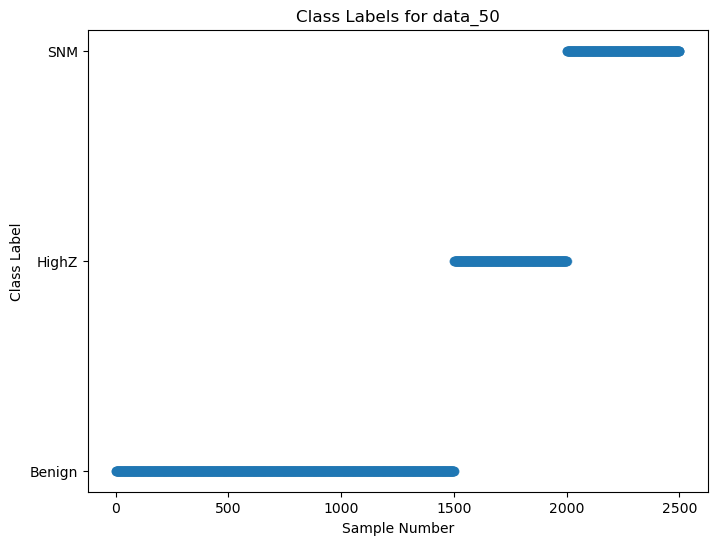

In [553]:
# Save class labels and material labels for later use
class_labels_50 = data_50['class_label'].values
#print("\nUnique class labels in data_50:", np.unique(class_labels_50)) # 3 different classes: Benign, HighZ, SNM

# Create sample numbers for plotting
sample_numbers = np.linspace(1, len(class_labels_50), len(class_labels_50)) # Sample numbers from 1 to number of samples

# plot by class label
plt.figure(figsize=(8, 6))
plt.scatter(sample_numbers, class_labels_50, alpha=0.6)
plt.xlabel('Sample Number')
plt.ylabel('Class Label')
plt.title('Class Labels for data_50')
plt.show()

Plotting by material (4 clusters, hoping to match)

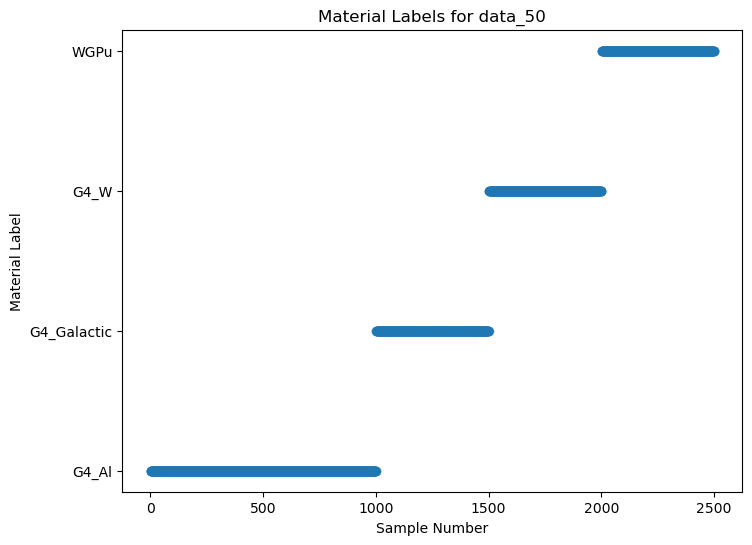

In [554]:
# save materials labels
material_labels_50 = data_50['snmMaterial'].values
#print("\nUnique material labels in data_50:", np.unique(material_labels_50)) # 4 different materials: Al, Galactic, W, Pu

plt.figure(figsize=(8, 6))
plt.scatter(sample_numbers, material_labels_50, alpha=0.6)
plt.xlabel('Sample Number')
plt.ylabel('Material Label')
plt.title('Material Labels for data_50')
plt.show()

Save inputs

In [555]:
# All predictive data (Previous columns are sampling data, so I'm starting from column 8)
X = data_95.iloc[:, 8:]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Begin actual ML tests

# A) Unsupervised

Test unsupervised clustering for 3 and 4 clusters (class vs material)

In [556]:
# Testing 3 clusters, and comparing against the true class labels (3 classes)
km3 = KMeans(n_clusters=3, n_init=30)
km3.fit(X)
kmlabels3 = km3.labels_

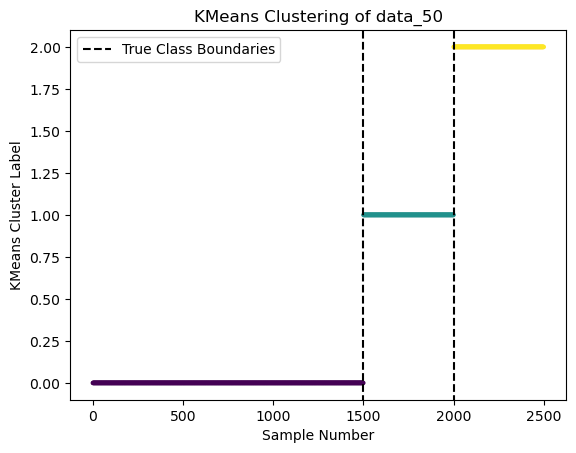

In [557]:
plt.scatter(sample_numbers, kmlabels3, c=kmlabels3, alpha=0.6, s=5, cmap='viridis')
plt.xlabel('Sample Number')
plt.ylabel('KMeans Cluster Label')
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('KMeans Clustering of data_50')
plt.legend()
plt.show()


In [558]:
# Testing 5 clusters, and comparing against the true class labels (3 classes)

km5 = KMeans(n_clusters=5, n_init=30, random_state=1)
km5.fit(X)
kmlabels5 = km5.labels_

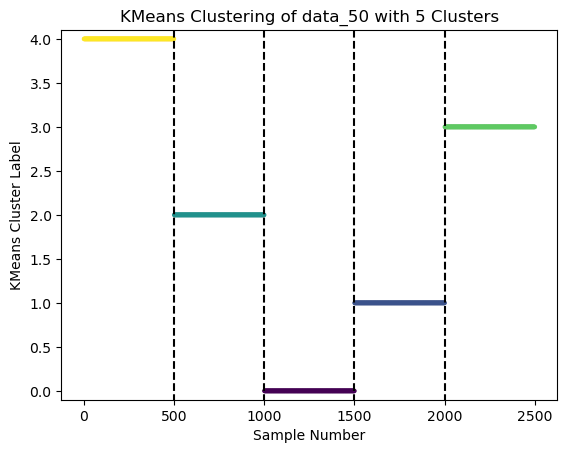

In [559]:
plt.scatter(sample_numbers, kmlabels5, alpha=0.6, c=kmlabels5, s=5, cmap='viridis')
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.xlabel('Sample Number')
plt.ylabel('KMeans Cluster Label')
plt.title('KMeans Clustering of data_50 with 5 Clusters')
plt.show()


In [560]:
AMI_km3 = adjusted_mutual_info_score(class_labels_50, kmlabels3)
ARI_km3 = adjusted_rand_score(class_labels_50, kmlabels3)
accuracy_km3 = accuracy_score(class_labels_50, kmlabels3)

print(f"KMeans with 3 clusters - AMI: {AMI_km3:.4f}, ARI: {ARI_km3:.4f}, Accuracy: {accuracy_km3:.4f}")

AMI_km5 = adjusted_mutual_info_score(material_labels_50, kmlabels5)
ARI_km5 = adjusted_rand_score(material_labels_50, kmlabels5)
accuracy_km5 = accuracy_score(material_labels_50, kmlabels5)

print(f"KMeans with 5 clusters - AMI: {AMI_km5:.4f}, ARI: {ARI_km5:.4f}, Accuracy: {accuracy_km5:.4f}")

KMeans with 3 clusters - AMI: 1.0000, ARI: 1.0000, Accuracy: 0.0000
KMeans with 5 clusters - AMI: 0.9056, ARI: 0.7823, Accuracy: 0.0000


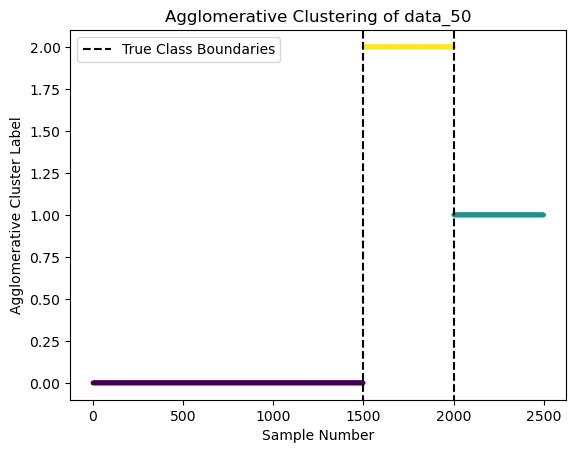

In [604]:
ac = AgglomerativeClustering(n_clusters=3)
aclusters = ac.fit_predict(X)
aclabels = ac.labels_

plt.scatter(sample_numbers, aclusters, c=aclusters, alpha=0.6, s=5, cmap='viridis')
plt.xlabel('Sample Number')
plt.ylabel('Agglomerative Cluster Label')
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Agglomerative Clustering of data_50')
plt.legend()
plt.show()

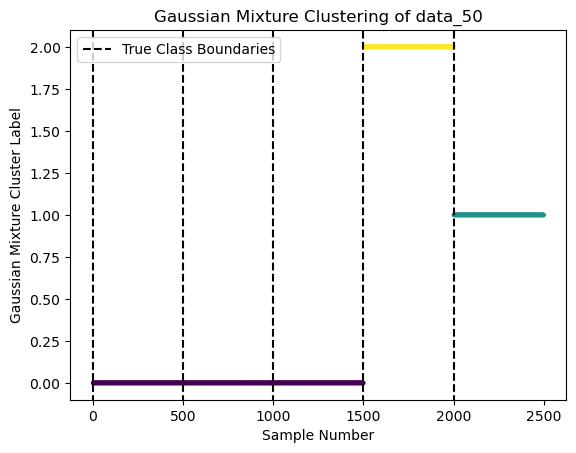

In [ ]:
# not set seed, and occassionally get interesting result that the 2nd Al set more closely aligns with high Z than the benign class

gm = GaussianMixture(n_components=3, random_state=)
gm.fit(X)
gmlabels = gm.predict(X)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.6, s=5, cmap='viridis')
plt.xlabel('Sample Number')
plt.ylabel('Gaussian Mixture Cluster Label')
plt.vlines(x=[0, 500, 1000, 1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Gaussian Mixture Clustering of data_50')
plt.legend()
plt.show()

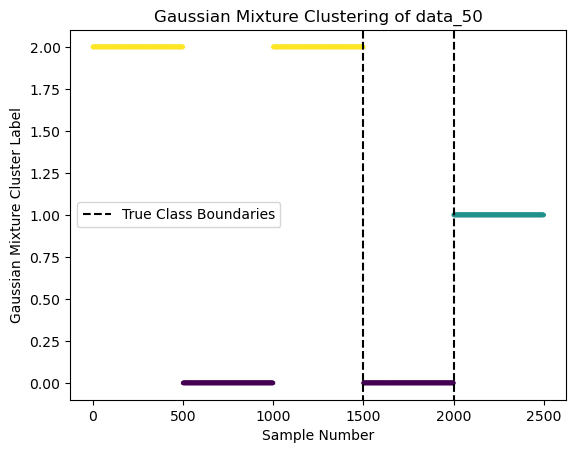

In [563]:
# not set seed, and occassionally get interesting result that the 2nd Al set more closely aligns with high Z than the benign class

gm = GaussianMixture(n_components=3, random_state=5)
gm.fit(X)
gmlabels = gm.predict(X)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.6, s=5, cmap='viridis')
plt.xlabel('Sample Number')
plt.ylabel('Gaussian Mixture Cluster Label')
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Gaussian Mixture Clustering of data_50')
plt.legend()
plt.show()

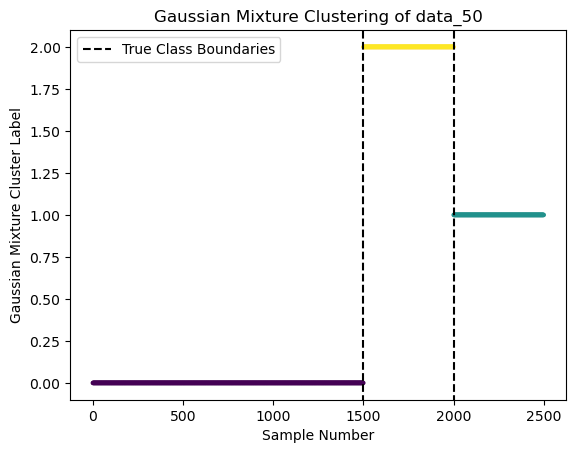

In [564]:
# not set seed, and occassionally get interesting result that the 2nd Al set more closely aligns with high Z than the benign class

gm = GaussianMixture(n_components=3, random_state=2)
gm.fit(X)
gmlabels = gm.predict(X)
plt.scatter(sample_numbers, gmlabels, c=gmlabels, alpha=0.6, s=5, cmap='viridis')
plt.xlabel('Sample Number')
plt.ylabel('Gaussian Mixture Cluster Label')
plt.vlines(x=[1500, 2000], ymin=-.25, ymax = 2.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 2.1)
plt.title('Gaussian Mixture Clustering of data_50')
plt.legend()
plt.show()

# B) Supervised

Random Forest

In [565]:
encoded_class_labels_50 = LabelEncoder().fit_transform(class_labels_50)
encoded_material_labels_50 = LabelEncoder().fit_transform(material_labels_50)

Y = np.column_stack((encoded_class_labels_50, encoded_material_labels_50))

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

rf = RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_split=2, random_state=42)

rf.fit(X_train, Y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [566]:
Y_pred = rf.predict(X_test)

print("Class accuracy:", accuracy_score(Y_test[:,0], Y_pred[:,0]))
print("Material accuracy:", accuracy_score(Y_test[:,1], Y_pred[:,1]))

print("Counts of predicted class labels:", Counter(Y_pred[:,0]))
print("Counts of predicted material labels:", Counter(Y_pred[:,1]))


Class accuracy: 1.0
Material accuracy: 1.0
Counts of predicted class labels: Counter({np.int64(0): 296, np.int64(1): 111, np.int64(2): 93})
Counts of predicted material labels: Counter({np.int64(0): 188, np.int64(2): 111, np.int64(1): 108, np.int64(3): 93})


(42,)


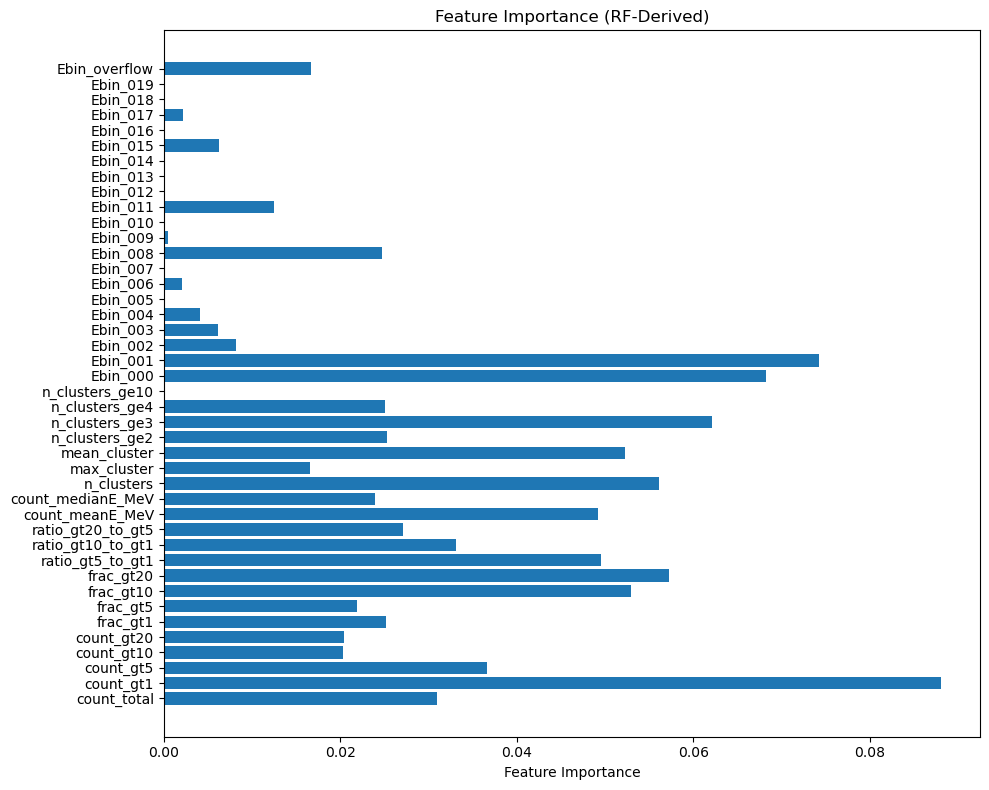

In [ ]:
feature_labels = [X.columns[i] for i in range(X.shape[1])]

#print(rf.feature_importances_.shape)

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), rf.feature_importances_)
plt.yticks(range(len(feature_labels)), feature_labels)
plt.xlabel("Feature Importance")
plt.title("Feature Importance (RF-Derived)")
plt.tight_layout()
plt.show()

Gradient Boosting

In [568]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

gb_multi = MultiOutputClassifier(gb)

gb_multi.fit(X_train, Y_train)

,estimator,GradientBoost...ndom_state=42)
,n_jobs,None
,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3


In [569]:
Y_pred = gb_multi.predict(X_test)

print("Class accuracy:", accuracy_score(Y_test[:,0], Y_pred[:,0]))
print("Material accuracy:", accuracy_score(Y_test[:,1], Y_pred[:,1]))

print("Counts of predicted class labels:", Counter(Y_pred[:,0]))
print("Counts of predicted material labels:", Counter(Y_pred[:,1]))

Class accuracy: 1.0
Material accuracy: 1.0
Counts of predicted class labels: Counter({np.int64(0): 296, np.int64(1): 111, np.int64(2): 93})
Counts of predicted material labels: Counter({np.int64(0): 188, np.int64(2): 111, np.int64(1): 108, np.int64(3): 93})


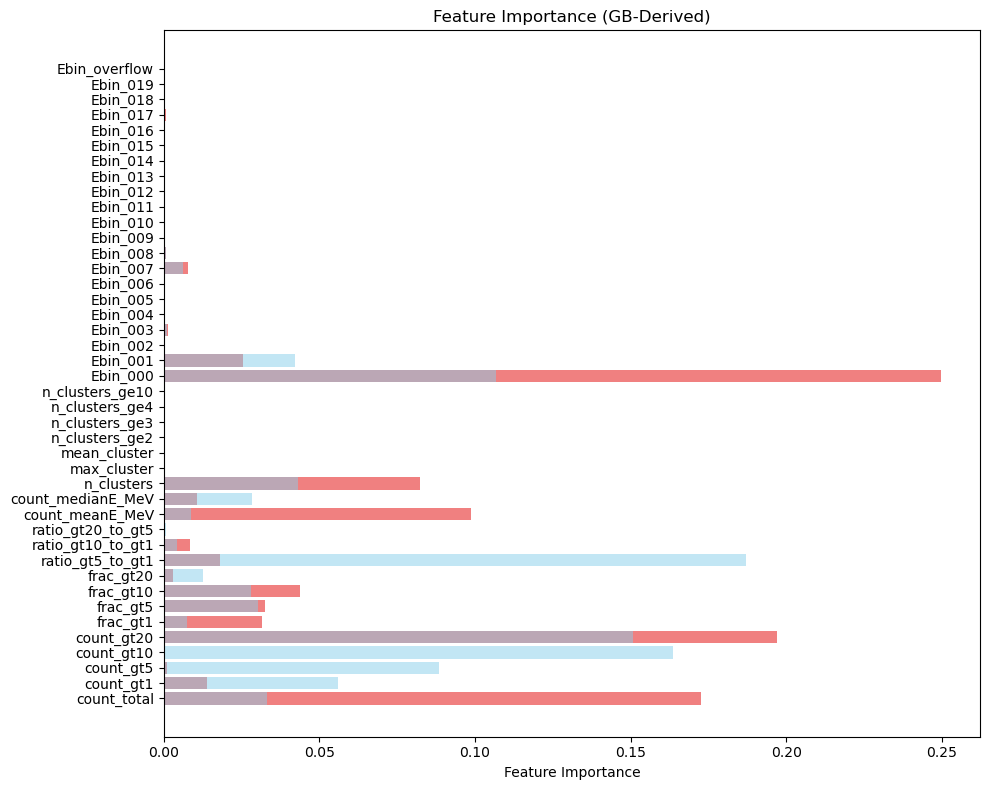

In [607]:
feature_labels = [X.columns[i] for i in range(X.shape[1])]

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), gb_multi.estimators_[0].feature_importances_, alpha=1, color="lightcoral")
plt.barh(range(len(feature_labels)), gb_multi.estimators_[1].feature_importances_, alpha=0.5, color="skyblue")
plt.yticks(range(len(feature_labels)), feature_labels)
plt.xlabel("Feature Importance")
plt.title("Feature Importance (GB-Derived)")
plt.tight_layout()
plt.show()

### TRYING ON NEW DATA

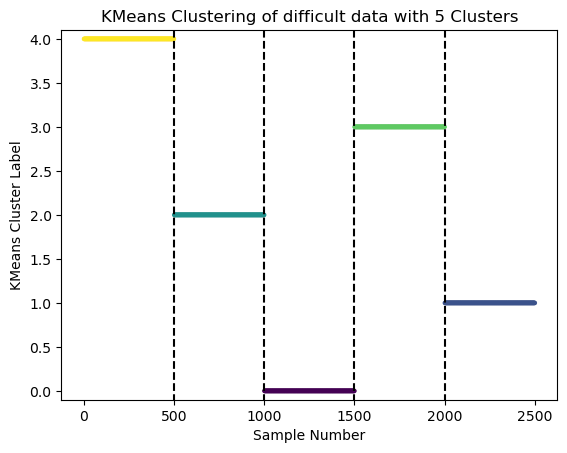

KMeans with 5 clusters - AMI: 0.9056, ARI: 0.7823, Accuracy: 0.0000


In [638]:
data = pd.read_csv("C:\\Users\\benja\\Downloads\\tier3_resp035_thr05_smear_ap9avg_sc50.csv")

X2 = data.iloc[:, 8:]
Y2 = np.column_stack((data['class_label'].values, data['snmMaterial'].values))

km5 = KMeans(n_clusters=5, n_init=30, random_state=1)
km5.fit(X2)
kmlabels_new = km5.labels_

# Save class labels and material labels for later use
class_labels = data['class_label'].values
material_labels = data['snmMaterial'].values
#print("\nUnique class labels in data_50:", np.unique(class_labels_50)) # 3 different classes: Benign, HighZ, SNM

# Create sample numbers for plotting
sample_numbers = np.linspace(1, len(class_labels), len(class_labels)) # Sample numbers from 1 to number of samples

plt.scatter(sample_numbers, kmlabels_new, alpha=0.6, c=kmlabels_new, s=5, cmap='viridis')
plt.vlines(x=[500, 1000, 1500, 2000], ymin=-.25, ymax = 4.25, color='k', linestyle='--', label='True Class Boundaries')
plt.ylim(-0.1, 4.1)
plt.xlabel('Sample Number')
plt.ylabel('KMeans Cluster Label')
plt.title('KMeans Clustering of difficult data with 5 Clusters')
plt.show()

AMI_km5 = adjusted_mutual_info_score(material_labels, kmlabels_new)
ARI_km5 = adjusted_rand_score(material_labels, kmlabels_new)
accuracy_km5 = accuracy_score(material_labels, kmlabels_new)

print(f"KMeans with 5 clusters - AMI: {AMI_km5:.4f}, ARI: {ARI_km5:.4f}, Accuracy: {accuracy_km5:.4f}")



In [628]:
encoded_class_labels = LabelEncoder().fit_transform(class_labels)
encoded_material_labels= LabelEncoder().fit_transform(material_labels)

X_train2, X_test2, Y_train2, Y_test2 = train_test_split(X2, Y2, test_size=0.2, random_state=42)

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

gb_multi = MultiOutputClassifier(gb)

gb_multi.fit(X_train2, Y_train2)

Y_pred2 = gb_multi.predict(X_test2)

print("Class accuracy:", accuracy_score(Y_test2[:,0], Y_pred2[:,0]))
print("Material accuracy:", accuracy_score(Y_test2[:,1], Y_pred2[:,1]))

print("Counts of predicted class labels:", Counter(Y_pred2[:,0]))
print("Counts of predicted material labels:", Counter(Y_pred2[:,1]))

Class accuracy: 1.0
Material accuracy: 0.98
Counts of predicted class labels: Counter({'Benign': 296, 'HighZ': 111, 'SNM': 93})
Counts of predicted material labels: Counter({'G4_Al': 190, 'G4_W': 111, 'G4_Galactic': 106, 'WGPu': 93})


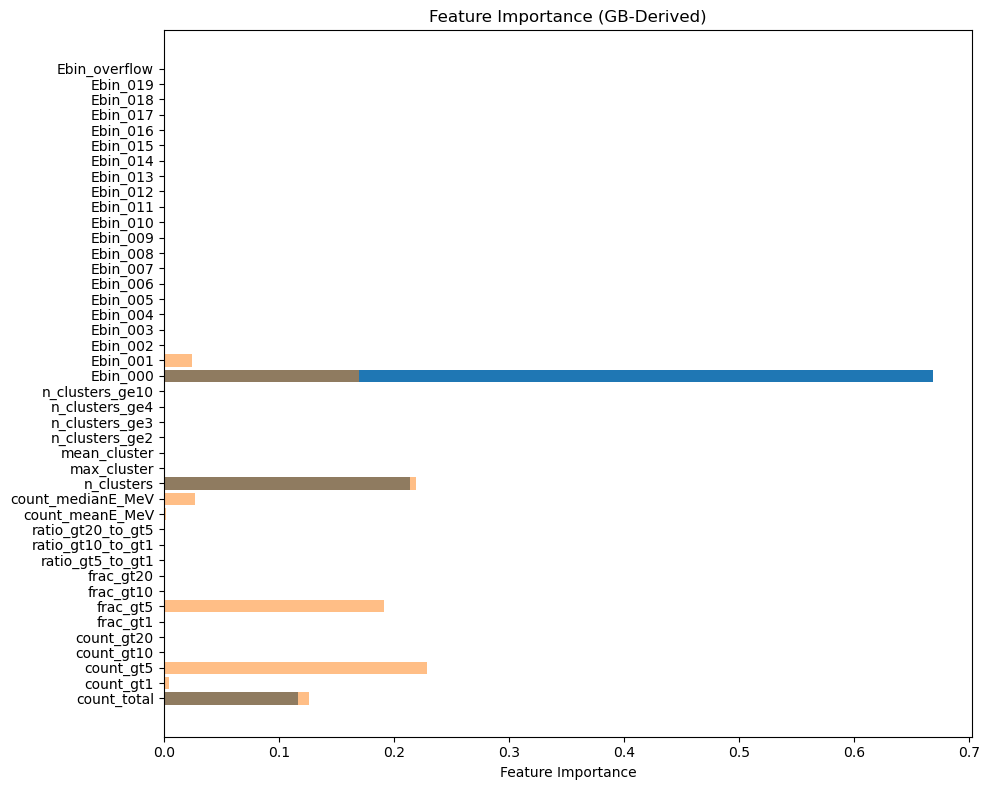

In [629]:
feature_labels = [X.columns[i] for i in range(X.shape[1])]

plt.figure(figsize=(10, 8))
plt.barh(range(len(feature_labels)), gb_multi.estimators_[0].feature_importances_, alpha=1)
plt.barh(range(len(feature_labels)), gb_multi.estimators_[1].feature_importances_, alpha=0.5)
plt.yticks(range(len(feature_labels)), feature_labels)
plt.xlabel("Feature Importance")
plt.title("Feature Importance (GB-Derived)")
plt.tight_layout()
plt.show()